In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# E-Commerce Reviews | Sentiment Analysis

### Customer Feedback Analysis Using Python and VADER

This project explores customer reviews from a women's clothing e-commerce dataset to better understand customer satisfaction, purchasing experiences and sentiment patterns.

By applying NLP techniques, the analysis aims to classify customer reviews into positive, negative, and neutral sentiments and investigate how these sentiments relate to product ratings, recommendations, and clothing categories.

The processed data will later be used to develop an interactive Tableau dashboard for visualizing key insights.

In [33]:
data = pd.read_csv("../data/Womens Clothing E-Commerce Reviews.csv")
data.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [34]:
data.shape

(23486, 11)

In [35]:
data.describe()

,Unnamed: 0,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
count,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000
mean,11742.500000,918.118709,43.198544,4.196032,0.822362,2.535936
std,6779.968547,203.298980,12.279544,1.110031,0.382216,5.702202
min,0.000000,0.000000,18.000000,1.000000,0.000000,0.000000
25%,5871.250000,861.000000,34.000000,4.000000,1.000000,0.000000
50%,11742.500000,936.000000,41.000000,5.000000,1.000000,1.000000
75%,17613.750000,1078.000000,52.000000,5.000000,1.000000,3.000000
max,23485.000000,1205.000000,99.000000,5.000000,1.000000,122.000000


### Initial observations
- The dataset contains 23486 records & 11 columns
- Customer ratings range from 1 to 5, with an average rating of approximately 4.20
- The average customer age is approximately 43 years
- The median rating is 5, suggesting that customer ratings are generally high
- The dataset contains both numerical and categorical variables

In [36]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 9.5 MB


### Assesing the data: missing values, duplicates, unnecessary columns

In [37]:
data.isnull().sum()

Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64

In [38]:
missing_values = pd.DataFrame({
    'Missing count': data.isnull().sum(),
    'Missing %': (data.isnull().sum() / len(data)) * 100
})

missing_values = missing_values.sort_values(
    by='Missing %',
    ascending=False
)

missing_values

,Missing count,Missing %
Title,3810,16.222430
Review Text,845,3.597888
Department Name,14,0.059610
Class Name,14,0.059610
Division Name,14,0.059610
Unnamed: 0,0,0.000000
Clothing ID,0,0.000000
Age,0,0.000000
Rating,0,0.000000
Recommended IND,0,0.000000


In [39]:
print(data['Department Name'].unique())
print(data['Class Name'].unique())
print(data['Division Name'].unique())

<ArrowStringArray>
['Intimate', 'Dresses', 'Bottoms', 'Tops', 'Jackets', 'Trend', nan]
Length: 7, dtype: str
<ArrowStringArray>
[     'Intimates',        'Dresses',          'Pants',        'Blouses',
          'Knits',      'Outerwear',         'Lounge',       'Sweaters',
         'Skirts',     'Fine gauge',          'Sleep',        'Jackets',
           'Swim',          'Trend',          'Jeans',        'Legwear',
         'Shorts',       'Layering', 'Casual bottoms',              nan,
       'Chemises']
Length: 21, dtype: str
<ArrowStringArray>
['Initmates', 'General', 'General Petite', nan]
Length: 4, dtype: str


In [40]:
data = data.dropna(subset=['Review Text'])
data.shape

(22641, 11)

In [41]:
category_columns = [
    'Division Name',
    'Department Name',
    'Class Name'
]

data[category_columns] = data[category_columns].fillna('Unknown')

In [42]:
data.isnull().sum()

Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      2966
Review Text                   0
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                 0
Department Name               0
Class Name                    0
dtype: int64

Rows with missing **Review Text** are removed, since textual feedback is essential for  sentiment analysis.
Missing titles are retained, as they are not required for the analysis.

Missing values in the **Division Name**, **Department Name**, and **Class Name** columns are replaced with **"Unknown"** to preserve customer reviews that contain valuable information but lack product category details.

Since these columns are categorical, using **"Unknown"** allows us to retain the records without introducing potentially incorrect category assignments.

In [43]:
print(data.duplicated().sum())

0


In [44]:
data = data.drop(columns=['Unnamed: 0'])

In [46]:
data.head()

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


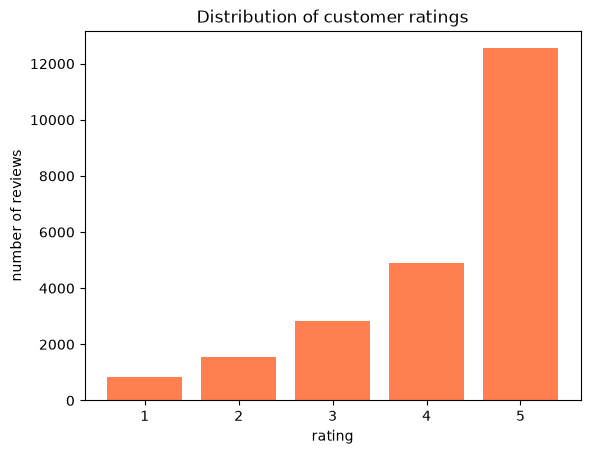

In [64]:
plt.hist(
    data['Rating'],
    bins=np.arange(0.5, 6.5, 1),
    color='coral',
    rwidth=0.8
)

plt.title('Distribution of customer ratings')
plt.xlabel('rating')
plt.ylabel('number of reviews')
plt.show()

=> Five star reviews represent the largest proportion of the dataset
Ratings of 1 and 2 are considerably less frequent, suggesting that customers generally report positive experiences with the purchased products.

However, numerical ratings alone do not fully capture customer opinions. \
Sentiment analysis of written reviews will provide additional insights into customer satisfaction and help identify potential differences between ratings and expressed sentiment.

In [52]:
data['Review Length'] = data['Review Text'].str.len()

In [53]:
data.head()

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,Review Length
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,53
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,303
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,500
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,124
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,192


In [72]:
data.to_csv('../data/cleaned_reviews.csv', index=False)